# ScamBench-KK — feature engineering

Notebook 01 audited the dataset: what the three classes are, why `decision_class`
cannot serve as the label, that the labelling never contradicts the original flag,
how the 300 Kazakh conversations are spread across splits, and that the translation
has no wording drift. It answers *what is in this data*.

Three of its results are load-bearing here:

- the label was **derived** from `decision_class` and `should_trigger_scam_defense`, so
  neither can ever be an input — that is what section 1 below quantifies;
- each Kazakh row sits in **its source's split**, so a train-English / evaluate-Kazakh
  comparison is not contaminated;
- the 300 conversations exist in **both languages with identical structure**, which is
  what makes section 5 a measurement rather than an assumption.

This notebook answers *what can be fed to a model*, and the answer is narrower than
it looks. The feature table itself is built by `scripts/build_features.py`; this
notebook establishes why it is built that way, then checks the result.

Four things happen here:

1. **A label-leakage audit.** `label_3class` was derived from two columns. Anything
   downstream of the annotation reproduces the label rather than predicting it, and
   that is measured rather than asserted. (Note: notebook 01 section 3 audits *split*
   leakage, which is a different problem — same word, different thing.)
2. **Features from conversation text only** — structure, entities, surface shape,
   and bilingual keyword families.
3. **A signal check**, to show the features are not noise, and a side-by-side
   demonstration of what leakage does to a score.
4. **An English/Kazakh parity check.** 300 conversations exist in both languages, so
   "does this feature survive translation" is a question this dataset can answer.

Prerequisites:

```
python scripts/merge_kk.py     --labeled data/labeled --translation data/translation --out data/merged
python scripts/build_features.py --merged data/merged --out data/features
```

In [1]:
import json
import pathlib
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]
            if (p / "scripts").is_dir())
sys.path.insert(0, str(ROOT / "scripts"))

import build_features as bf

pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 60)

# Categorical slots 1-3 of the reference data-viz palette, in fixed order.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#dcdcd8"

CLASSES = ["LEGITIMATE", "SUSPICIOUS", "SCAM"]
CLASS_COLOR = {"LEGITIMATE": BLUE, "SUSPICIOUS": ORANGE, "SCAM": AQUA}
GROUP_COLOR = {"struct_": BLUE, "entity_": ORANGE, "surface_": AQUA, "lex_": MUTED}


def bare_axes(ax, xlabel=None):
    """Recessive grid on one axis, no box, muted ticks."""
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=MUTED, length=0)
    if xlabel:
        ax.set_xlabel(xlabel, color=MUTED, fontsize=9)
    return ax


merged = {s: pd.read_parquet(ROOT / "data" / "merged" / f"{s}.parquet")
          for s in ["train", "test", "validation"]}
corpus = pd.concat(merged.values(), ignore_index=True)
print(f"merged corpus: {len(corpus):,} rows, {corpus.shape[1]} columns")

merged corpus: 37,721 rows, 25 columns


## 1. The label-leakage audit

This is the part that decides whether the dataset is usable at all. It is **not** the
leakage check from notebook 01 — that one was about conversations straddling splits.
This one is about columns that contain the answer.

`label_3class` was *derived* from `decision_class` and `should_trigger_scam_defense`
(notebook 01, section 1). So those two columns do not predict the label — they
**are** the label, rewritten. The same goes for everything else produced by or
alongside the annotation.

The measure below is simple: if you knew only this column, how often would the label
be pinned down? A column scoring near 100% is not a feature.

But the cut is made on **provenance, not on a threshold**. `needs_review` only
determines the label 49.7% of the time and is still excluded, because our own
labelling rule sets it; `pipeline_version` scores higher and is excluded for a
different reason — it is build metadata that a detector never sees. The question is
always "could a system know this at runtime, before the label existed?"

In [2]:
def determines_label(column, frame=corpus):
    """Share of rows whose label is fixed once you know this column's value."""
    grouped = frame.groupby(column, observed=True).label_3class
    purity = grouped.agg(lambda s: s.value_counts().iloc[0] / len(s))
    sizes = frame.groupby(column, observed=True).size()
    return (purity * sizes).sum() / sizes.sum()


candidates = ["label_rule", "diagnostic_labels", "unsafe_signals", "decision_class",
              "chosen_action", "risk_indicators", "source_dataset",
              "should_trigger_scam_defense", "scenario_category", "pipeline_version",
              "reasoning_source", "style_variant", "source_pool", "needs_review",
              "language"]
audit = pd.DataFrame({
    "determines_label": [determines_label(c) for c in candidates],
    "n_unique": [corpus[c].nunique() for c in candidates],
}, index=candidates).sort_values("determines_label", ascending=False)
# What actually reaches the feature table, so the verdict is not a guess.
CARRIED = {"language", "style_variant", "source_pool"}

def verdict(column):
    if column in bf.LEAKING_COLUMNS:
        return "EXCLUDED (leak)"
    if column in CARRIED:
        return "carried through"
    return "not used (provenance)"

audit["verdict"] = [verdict(c) for c in audit.index]
audit["determines_label"] = (100 * audit.determines_label).round(1).astype(str) + "%"
audit

,determines_label,n_unique,verdict
label_rule,100.0%,7,EXCLUDED (leak)
diagnostic_labels,96.3%,851,EXCLUDED (leak)
unsafe_signals,92.1%,507,EXCLUDED (leak)
decision_class,90.5%,13,EXCLUDED (leak)
chosen_action,90.5%,15,EXCLUDED (leak)
risk_indicators,81.1%,104,EXCLUDED (leak)
should_trigger_scam_defense,79.1%,2,EXCLUDED (leak)
source_dataset,78.9%,199,EXCLUDED (leak)
scenario_category,73.4%,154,EXCLUDED (leak)
pipeline_version,59.8%,22,not used (provenance)


In [3]:
# The pair the label was actually built from.
pair = corpus.groupby(["decision_class", "should_trigger_scam_defense"], observed=True)
purity = pair.label_3class.agg(lambda s: s.value_counts().iloc[0] / len(s))
sizes = pair.size()
print(f"(decision_class, should_trigger_scam_defense) determines the label "
      f"{(purity * sizes).sum() / sizes.sum():.2%} of the time")
print()
print("Free-text columns are excluded too -- not measurable this way, but written")
print("by an annotator who already knew the answer:")
for column in ["response_text", "explanation", "reasoning_trace"]:
    print(f"  {column:<18} {bf.LEAKING_COLUMNS[column]}")
print()
print(f"{len(bf.LEAKING_COLUMNS)} of {corpus.shape[1]} columns excluded.")
print("What is left is the conversation itself, plus metadata carrying no annotation:")
print("  messages, system_prompt, language, style_variant, source_pool")

(decision_class, should_trigger_scam_defense) determines the label 99.99% of the time

Free-text columns are excluded too -- not measurable this way, but written
by an annotator who already knew the answer:
  response_text      the agent's reply, written knowing the right answer
  explanation        the rationale for the label
  reasoning_trace    chain of thought toward the labelled decision

13 of 25 columns excluded.
What is left is the conversation itself, plus metadata carrying no annotation:
  messages, system_prompt, language, style_variant, source_pool


### Why `scenario_category` is excluded too

It is tempting to keep: 154 values, only 73% determining. But it is the *attack
type* — an annotation describing what the conversation is, assigned by whoever
built the corpus. A detector at runtime does not know it. Keeping it would be
training a model to read the answer key rather than the conversation.

In [4]:
category_vs_label = pd.crosstab(corpus.scenario_category, corpus.label_3class)
top = category_vs_label.loc[category_vs_label.sum(axis=1).nlargest(6).index]
display(top.reindex(columns=CLASSES).fillna(0).astype(int))
print("`legitimate` is almost perfectly one class -- that is an annotation, not a signal.")

label_3class,LEGITIMATE,SUSPICIOUS,SCAM
scenario_category,,,
legitimate,14174,1,0
social-engineering,2443,6705,2867
prompt-injection,714,1191,1710
research-assisted,642,1212,503
phishing-link,277,735,174
secret-exfiltration,18,129,610


`legitimate` is almost perfectly one class -- that is an annotation, not a signal.


## 2. The features

Built by `scripts/build_features.py`, which is imported here rather than copied, so
the notebook cannot drift from what actually produced the table.

Four groups, named by prefix so the grouping survives into any later model:

| Prefix | What it measures | Translation-invariant? |
|---|---|---|
| `struct_` | message count, roles, who speaks last | yes, by construction |
| `entity_` | links, emails, handles, phones, amounts, codes | yes, by construction |
| `surface_` | lengths, case, digits, punctuation, leetspeak | no — measures the writing system |
| `lex_` | keyword families: urgency, credentials, payment, authority, secrecy, instruction override, verification pushback | only in a language the lexicon covers |

The lexicon is bilingual. English matches on word boundaries; Kazakh is
agglutinative, so it matches on stems — `раста` covers растау, растаңыз, расталды.
A monolingual lexicon would score zero on half the data without erroring, which is
the kind of failure that does not announce itself.

In [5]:
features = {s: pd.read_parquet(ROOT / "data" / "features" / f"{s}.parquet")
            for s in ["train", "test", "validation"]}
feat = pd.concat(features.values(), ignore_index=True)
cols = bf.feature_columns(feat)

print(f"{len(feat):,} rows, {len(cols)} features")
for prefix in ["struct_", "entity_", "surface_", "lex_"]:
    names = [c for c in cols if c.startswith(prefix)]
    print(f"  {prefix:<10} {len(names):>2}  {', '.join(n[len(prefix):] for n in names[:6])}"
          + (" ..." if len(names) > 6 else ""))

assert not set(bf.LEAKING_COLUMNS) & set(feat.columns), "a leaking column reached the features"
print("\nno leaking column is present in the feature table")
feat[["id", "language", "label_3class"] + cols[:6]].head()

37,721 rows, 54 features
  struct_     8  n_messages, n_user, n_assistant, n_system, n_tool, user_share ...
  entity_    17  n_url, has_url, n_email, has_email, n_handle, has_handle ...
  surface_   13  total_chars, mean_msg_chars, max_msg_chars, n_words, mean_word_len, user_char_share ...
  lex_       16  urgency, urgency_in_user, credential, credential_in_user, payment, payment_in_user ...

no leaking column is present in the feature table


,id,language,label_3class,struct_n_messages,struct_n_user,struct_n_assistant,struct_n_system,struct_n_tool,struct_user_share
0,generated::cultureth::c1856fe02165ccba,th,SUSPICIOUS,10,5,4,1,0,0.5
1,generated::cultureth::3e276a4fd1fb9235,th,SCAM,4,2,1,1,0,0.5
2,generated::cultureth::3f5ece6c5ecda015,th,SCAM,4,2,1,1,0,0.5
3,generated::cultureth::f5ce3bb48bd38dd6,th,SCAM,4,2,1,1,0,0.5
4,generated::cultureth::07f0baa354921048,th,SUSPICIOUS,18,9,8,1,0,0.5


In [6]:
# One worked example, so the numbers are not abstract.
example = corpus[(corpus.language == "en") & (corpus.label_3class == "SCAM")].iloc[0]
messages = json.loads(example.messages)
print(f"id: {example.id}   label: {example.label_3class}   style: {example.style_variant}")
print(f"{len(messages)} messages, first user turn:")
first_user = next((m["content"] for m in messages if m["role"] == "user"), "")
print("   " + first_user[:200].replace("\n", " ") + ("..." if len(first_user) > 200 else ""))
print()
computed = bf.conversation_features(messages, example.system_prompt or "")
nonzero = {k: v for k, v in computed.items() if v}
print("non-zero features:")
for name, value in list(nonzero.items())[:18]:
    print(f"   {name:<34} {value}")

id: generated::adminoverride::2a49ea4b11ebc07d   label: SCAM   style: broken_english
4 messages, first user turn:
   Hello, this is urgent.

non-zero features:
   struct_n_messages                  4
   struct_n_user                      2
   struct_n_assistant                 1
   struct_n_system                    1
   struct_user_share                  0.5
   struct_last_is_user                1.0
   struct_has_system_prompt           1.0
   surface_total_chars                269
   surface_mean_msg_chars             66.5
   surface_max_msg_chars              143
   surface_n_words                    36
   surface_mean_word_len              6.166666666666667
   surface_user_char_share            0.8306451612903226
   surface_upper_ratio                0.027522935779816515
   surface_digit_ratio                0.011152416356877323
   surface_punct_ratio                0.03345724907063197
   surface_questions                  1
   surface_mean_sentence_len          9.0


## 3. Do the features separate the classes?

Mutual information against the label, computed on the **training split only** — the
test and validation splits are not touched here. Mutual information is used rather
than correlation because most of these features are counts with long tails and the
relationship is not expected to be linear.

In [7]:
from sklearn.feature_selection import mutual_info_classif

train = features["train"]
X = train[cols].to_numpy(dtype=float)
y = train.label_3class.to_numpy()

# subsample for speed; MI is k-NN based and the ranking is stable well before 30k rows
rng = np.random.default_rng(0)
idx = rng.choice(len(X), size=min(10_000, len(X)), replace=False)
mi = mutual_info_classif(X[idx], y[idx], random_state=0)

ranked = pd.Series(mi, index=cols).sort_values(ascending=False)
print("features carrying no information at all:",
      list(ranked[ranked <= 1e-6].index) or "none")
ranked.head(15).to_frame("mutual_information")

features carrying no information at all: ['entity_n_code', 'entity_has_handle', 'lex_secrecy', 'entity_has_email', 'struct_has_system_prompt', 'struct_n_tool']


,mutual_information
surface_max_msg_chars,0.149570
struct_last_is_user,0.077103
lex_families_present,0.070152
struct_n_messages,0.065446
surface_user_char_share,0.057653
struct_n_assistant,0.056822
surface_digit_ratio,0.055770
struct_user_share,0.055109
lex_urgency,0.054971
lex_urgency_in_user,0.052458


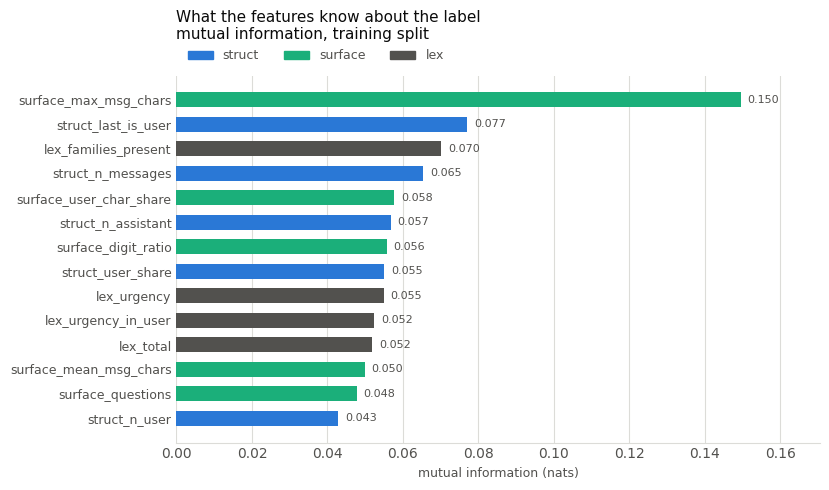

In [8]:
top = ranked.head(14).iloc[::-1]
colors = [next(c for p, c in GROUP_COLOR.items() if name.startswith(p)) for name in top.index]

fig, ax = plt.subplots(figsize=(8.4, 5.0))
ax.barh(range(len(top)), top.values, height=0.62, color=colors)
for i, value in enumerate(top.values):
    ax.text(value + top.max() * 0.012, i, f"{value:.3f}", va="center", fontsize=8, color=MUTED)

ax.set_yticks(range(len(top)))
ax.set_yticklabels(top.index, fontsize=9)
ax.set_title("What the features know about the label\nmutual information, training split",
             loc="left", color=INK, fontsize=11, pad=26)
bare_axes(ax, "mutual information (nats)")
ax.set_xlim(0, top.max() * 1.14)

present = [p for p in GROUP_COLOR if any(n.startswith(p) for n in top.index)]
handles = [plt.Rectangle((0, 0), 1, 1, color=GROUP_COLOR[p]) for p in present]
ax.legend(handles, [p.rstrip("_") for p in present], frameon=False, ncol=len(present),
          labelcolor=MUTED, fontsize=9, loc="lower left", bbox_to_anchor=(0, 1.005))
plt.tight_layout()
plt.show()

No `entity_` feature reaches the top ranks, which is itself a finding: whether a
conversation contains a link or an amount separates the classes far less than *how
it is shaped* — how long the longest message is, who speaks last, how many keyword
families appear. Scam and legitimate conversations both contain URLs and money.

## 4. Signal check — and two kinds of leakage

Not a model, a sanity check: if these features carried nothing, a classifier would sit
at the majority-class baseline.

Two things get measured at once, because the first was found by accident while running
the cross-lingual experiment in notebook 03.

**ScamBench's own splits leak.** An id is `<pool>::<conversation>::<row>`, and the
augmented pool rewrites a single conversation in up to 76 voices. Those rewrites are
assigned to splits independently, so **83% of validation rows have a twin of the same
conversation sitting in training**. A model does not have to generalise to score well;
it only has to recognise a sentence it already read in another register. That is a
property of the corpus, not of anything built here.
`scripts/make_group_split.py` produces `split_grouped`, keeping a whole conversation
family on one side of the line — same sizes, same class balance, zero families split.

**Our label leaks too**, which is what section 1 was about. The last row adds one
excluded column back and shows what it buys.


In [9]:
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score
from sklearn.preprocessing import OrdinalEncoder

grouped = pd.read_csv(ROOT / "data" / "splits" / "grouped_split.csv").set_index("id")
feat["split_grouped"] = feat.id.map(grouped.split_grouped)
corpus_by_id = corpus.set_index("id")


def score(split_column):
    train = feat[feat[split_column] == "train"]
    valid = feat[feat[split_column] == "validation"]
    X_train, X_valid = train[cols].to_numpy(float), valid[cols].to_numpy(float)
    y_train, y_valid = train.label_3class, valid.label_3class

    out = {}
    out["majority class"] = f1_score(
        y_valid, DummyClassifier(strategy="most_frequent")
        .fit(X_train, y_train).predict(X_valid), average="macro")
    out["text features only"] = f1_score(
        y_valid, HistGradientBoostingClassifier(max_iter=150, random_state=0)
        .fit(X_train, y_train).predict(X_valid), average="macro")

    encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    leak_train = encoder.fit_transform(corpus_by_id.loc[train.id, ["decision_class"]])
    leak_valid = encoder.transform(corpus_by_id.loc[valid.id, ["decision_class"]])
    out["+ decision_class (LEAKED)"] = f1_score(
        y_valid, HistGradientBoostingClassifier(max_iter=150, random_state=0)
        .fit(np.hstack([X_train, leak_train]), y_train)
        .predict(np.hstack([X_valid, leak_valid])), average="macro")
    return out


results = pd.DataFrame({
    "original split": score("split"),
    "grouped split": score("split_grouped"),
}).round(3)
display(results)

print("Read the second column. The first is inflated by restylings of the same")
print("conversation appearing on both sides of the split -- a flaw in the corpus,")
print("not in the features. Honest baseline: "
      f"{results.loc['text features only', 'grouped split']:.3f} macro-F1.")
print()
print("The last row is what this dataset looks like when the label-leakage audit is")
print("skipped. It is not a result; it is the label being read back.")

,original split,grouped split
majority class,0.222,0.221
text features only,0.783,0.650
+ decision_class (LEAKED),0.986,0.961


Read the second column. The first is inflated by restylings of the same
conversation appearing on both sides of the split -- a flaw in the corpus,
not in the features. Honest baseline: 0.650 macro-F1.

The last row is what this dataset looks like when the label-leakage audit is
skipped. It is not a result; it is the label being read back.


## 5. English / Kazakh parity

This is what the 300 translated conversations make possible. Each exists in both
languages with identical structure and identical entities, so for any feature the
question "does this survive translation?" has a measurable answer — and a feature
that does not survive cannot be trusted to transfer across languages.

In [10]:
kazakh = feat[feat.language == "kk"]
english = feat.set_index("id")
print(f"{len(kazakh)} paired conversations")

rows = []
for prefix in ["struct_", "entity_", "surface_", "lex_"]:
    group = [c for c in cols if c.startswith(prefix)]
    agree = sum(1 for r in kazakh.itertuples()
                if all(getattr(r, c) == english.loc[r.translated_from, c] for c in group))
    rows.append({"group": prefix, "features": len(group), "pairs identical": agree,
                 "share": agree / len(kazakh)})
parity = pd.DataFrame(rows).set_index("group")
parity["share"] = (100 * parity["share"]).round(0).astype(int).astype(str) + "%"
parity

300 paired conversations


,features,pairs identical,share
group,,,
struct_,8,300,100%
entity_,17,292,97%
surface_,13,0,0%
lex_,16,39,13%


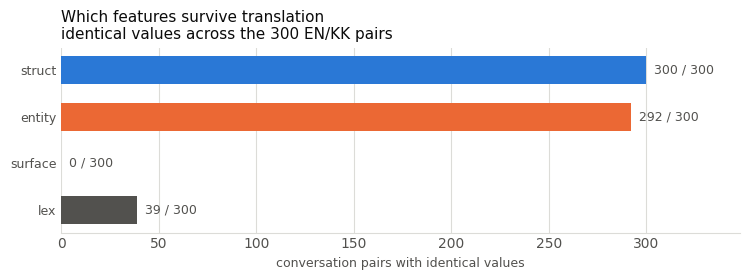

In [11]:
fig, ax = plt.subplots(figsize=(7.6, 2.9))
order = parity.index[::-1]
values = parity.loc[order, "pairs identical"]
ax.barh(range(len(order)), values, height=0.6,
        color=[GROUP_COLOR[p] for p in order])
for i, value in enumerate(values):
    ax.text(value + 4, i, f"{int(value)} / {len(kazakh)}", va="center", fontsize=9, color=MUTED)

ax.set_yticks(range(len(order)))
ax.set_yticklabels([p.rstrip("_") for p in order], fontsize=9)
ax.set_title("Which features survive translation\nidentical values across the 300 EN/KK pairs",
             loc="left", color=INK, fontsize=11)
bare_axes(ax, "conversation pairs with identical values")
ax.set_xlim(0, len(kazakh) * 1.16)
plt.tight_layout()
plt.show()

### Reading that chart

- **`struct_` 300/300.** Exactly as designed: the assembler copies message count,
  roles and order from the source, so a translation can differ only in message text.
- **`entity_` 292/300.** Should be 300, and the 8 exceptions are instructive. The
  entity counts are taken on text with leetspeak blanked first — without that,
  `455157` ("assist") counts as a six-digit code in the English and vanishes in the
  Kazakh, and leetspeak rows look like they carry data they do not. Kazakh
  morphology caused the mirror-image problem: `$6370-тен` makes `6370-` match the
  code pattern, so a code now has to contain a letter. The residual 8 are genuine:
  English `1920s` has no word boundary, Kazakh `1920 жылдар` does.
- **`surface_` 0/300.** Expected. These measure the writing system — character
  counts, case, punctuation density — and Kazakh is not English. Useful
  *within* a language, never comparable across one.
- **`lex_` 39/300.** The bilingual lexicon fires in both languages but not at equal
  rates, because the languages do not say things the same number of times. The
  cell below shows what a monolingual lexicon would have done instead.

In [12]:
import re

en_only = {f: re.compile("|".join(rf"\b{re.escape(t)}" for t in terms["en"]), re.I)
           for f, terms in bf.LEXICON.items()}

def english_only_hits(row):
    messages = json.loads(corpus.set_index("id").loc[row, "messages"])
    text = "\n".join(m.get("content") or "" for m in messages)
    return sum(len(p.findall(text)) for p in en_only.values())

sample = kazakh.head(60)
kk_hits = [english_only_hits(r.id) for r in sample.itertuples()]
en_hits = [english_only_hits(r.translated_from) for r in sample.itertuples()]

print("An English-only lexicon, run over both languages (60 pairs):")
print(f"  total hits on the English rows: {sum(en_hits)}")
print(f"  total hits on the Kazakh rows:  {sum(kk_hits)}")
print(f"  Kazakh rows scoring zero:       {sum(1 for h in kk_hits if h == 0)} / {len(sample)}")
print()
print("It does not error. It just quietly reports that Kazakh scam conversations")
print("contain no urgency, no credential requests and no payment demands.")

An English-only lexicon, run over both languages (60 pairs):
  total hits on the English rows: 54
  total hits on the Kazakh rows:  8
  Kazakh rows scoring zero:       52 / 60

It does not error. It just quietly reports that Kazakh scam conversations
contain no urgency, no credential requests and no payment demands.


## 6. Is the dataset ready?

**For features derived from conversation text, yes** — that is what this notebook
builds, and the signal check confirms they are not noise.

Three constraints to carry into any modelling:

1. **13 of 25 columns are unusable.** They are listed in
   `build_features.LEAKING_COLUMNS` with the reason for each, and
   `build_features.py` fails if any of them reaches the feature table.
2. **The classes are imbalanced** — roughly 50 / 29 / 21. Report macro-F1 or
   per-class scores; accuracy will flatter a model that ignores SCAM.
3. **The Kazakh rows are 300 of 37,721, under 1%.** They are an evaluation slice,
   not training material. The useful experiment is to train on English and evaluate
   zero-shot on the Kazakh pairs — the merge already guarantees each Kazakh row sits
   in its source's split, so that comparison is not contaminated.

What is *not* here, and would come next:

- **Text representations.** These 54 features are hand-built and interpretable.
  Character n-grams or a multilingual sentence encoder would likely be stronger, and
  the parity check above is the right way to test whether they transfer.
- **Per-message features.** Everything here is aggregated over the whole
  conversation. Where in a conversation the risk appears is probably informative and
  is currently thrown away.

## 7. What to say about this in the defence

### The 60-second version

> We could not just throw the columns at a model. Our label was *derived* from two
> of them, so we measured how much each column gives away: `decision_class` plus
> `should_trigger_scam_defense` pin the label down 99.99% of the time. Thirteen of
> twenty-five columns had to be dropped. We then built 54 features from the
> conversation text alone — structure, entities, surface shape, and keyword families
> in both English and Kazakh. To show it matters, we trained the same classifier
> twice: on the honest features, and with one leaked column added. The leaked
> version scores far higher and has learned nothing. Finally, because our 300
> conversations exist in both languages, we could measure which features survive
> translation rather than assume it.

### The one thing to put on a slide

The three-row score table from section 4: majority baseline, text features, and
text features plus one leaked column. It makes the whole argument in three numbers,
and it is the reason the leakage audit was worth doing.

### Questions to expect, and the honest answers

**"Why not use `scenario_category`? It is in the dataset."**
Because it is the attack type — an annotation, not an observation. A detector at
runtime never sees it. Using it is training the model to read the answer key.

**"Isn't dropping 13 columns throwing away information?"**
It is throwing away *the answer*. Those columns exist because an annotator already
decided what the conversation was. What is left is what a real system actually
receives: the conversation.

**"Your features are hand-crafted. Why not just use a transformer?"**
Likely stronger, and it is the obvious next step. Hand-built features are
interpretable, which is what let us catch two measurement bugs — leetspeak digits
being counted as codes, and Kazakh suffixes creating fake codes. We would not have
seen either through an embedding.

**"How do you know the features work on Kazakh?"**
We measured it, which this dataset uniquely allows. `struct_` is identical on
300/300 pairs, `entity_` on 292/300, `surface_` on 0/300 and `lex_` on 39/300. The
`surface_` result is not a bug — those features measure the writing system, so they
are usable within a language and never across one.

**"What is still missing?"**
Three things, and we would say them before being asked: no native speaker has
reviewed the Kazakh for fluency; the classes are imbalanced, so we report macro-F1
rather than accuracy; and the Kazakh rows are under 1% of the corpus, so they are an
evaluation slice rather than training material.

### The thing worth volunteering

The entity parity check started at 286/300 and we treated the gap as a bug rather
than rounding it away. It turned out to be two real defects in our own feature code,
in opposite directions, and fixing them took it to 292/300. The residual 8 are
genuine language differences — English `1920s` versus Kazakh `1920 жылдар` — and we
left them rather than tuning until the number looked clean.